In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from zoneinfo import ZoneInfo
from scipy.ndimage import median_filter
from scipy.signal import savgol_filter
from sklearn.linear_model import HuberRegressor

In [2]:
def load_time_mag_temp(filename, calibration=1.0, local_tz="Australia/Sydney",
                       temp_window=31, mag_window=101, mag_order=2):
    path = Path(filename)
    ext = path.suffix.lower()

    if path.is_dir():
        x, y, z = (np.load(path / f"{a}_nT.npy").astype(np.float64) for a in "xyz")
        ts = np.load(path / "timestamp.npy", allow_pickle=True)
        temp = np.load(path / "temp_c.npy").astype(np.float64)
    elif ext == ".csv":
        df = pd.read_csv(path)
        x, y, z = (df[f"{a}_nT"].to_numpy(np.float64) for a in "xyz")
        ts = df["timestamp_utc"].to_numpy()
        temp = df["temp_c"].to_numpy(np.float64)
    elif ext == ".npz":
        with np.load(path, allow_pickle=True) as npz:
            x, y, z = (npz[f"{a}_nT"].astype(np.float64) for a in "xyz")
            ts = npz["timestamp"]
            temp = npz["temp_c"].astype(np.float64)
    else:
        raise ValueError(f"Unsupported file type: {ext}")

    if np.issubdtype(ts.dtype, np.number):
        time = pd.to_datetime(ts, unit="s", utc=True)
    else:
        time = pd.to_datetime(ts, utc=True)
    time = time.tz_convert(ZoneInfo(local_tz))

    mag = calibration * np.sqrt(x**2 + y**2 + z**2)

    good = np.isfinite(mag) & np.isfinite(temp)
    time, mag, temp = time[good], mag[good], temp[good]

    temp_s = median_filter(temp, size=temp_window, mode="nearest")
    mag_s = savgol_filter(mag, window_length=mag_window, polyorder=mag_order)

    return time, mag, mag_s, temp_s

In [3]:
def correct_magnitude(mag_s, temp_s):
    m_ref = np.median(mag_s)
    T_ref = np.median(temp_s)
    dm = (mag_s - m_ref) / m_ref
    dT = temp_s - T_ref
    k = HuberRegressor(fit_intercept=False).fit(dT.reshape(-1, 1), dm).coef_[0]
    return mag_s / (1 + k * dT), k

In [4]:
def plot_correction(time, mag, temp_s, mag_corr):
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    axes[0].plot(time, mag, lw=0.8)
    axes[0].set_ylabel("Magnitude (nT)")
    axes[0].set_title("Raw magnitude")
    axes[1].plot(time, temp_s, lw=0.8, color="tab:red")
    axes[1].set_ylabel("Temperature (°C)")
    axes[1].set_title("Smoothed temperature")
    axes[2].plot(time, mag_corr, lw=0.8, color="tab:green")
    axes[2].set_ylabel("Magnitude (nT)")
    axes[2].set_title("Corrected magnitude")
    axes[2].set_xlabel("Time")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

k = 6.253e-04 per C


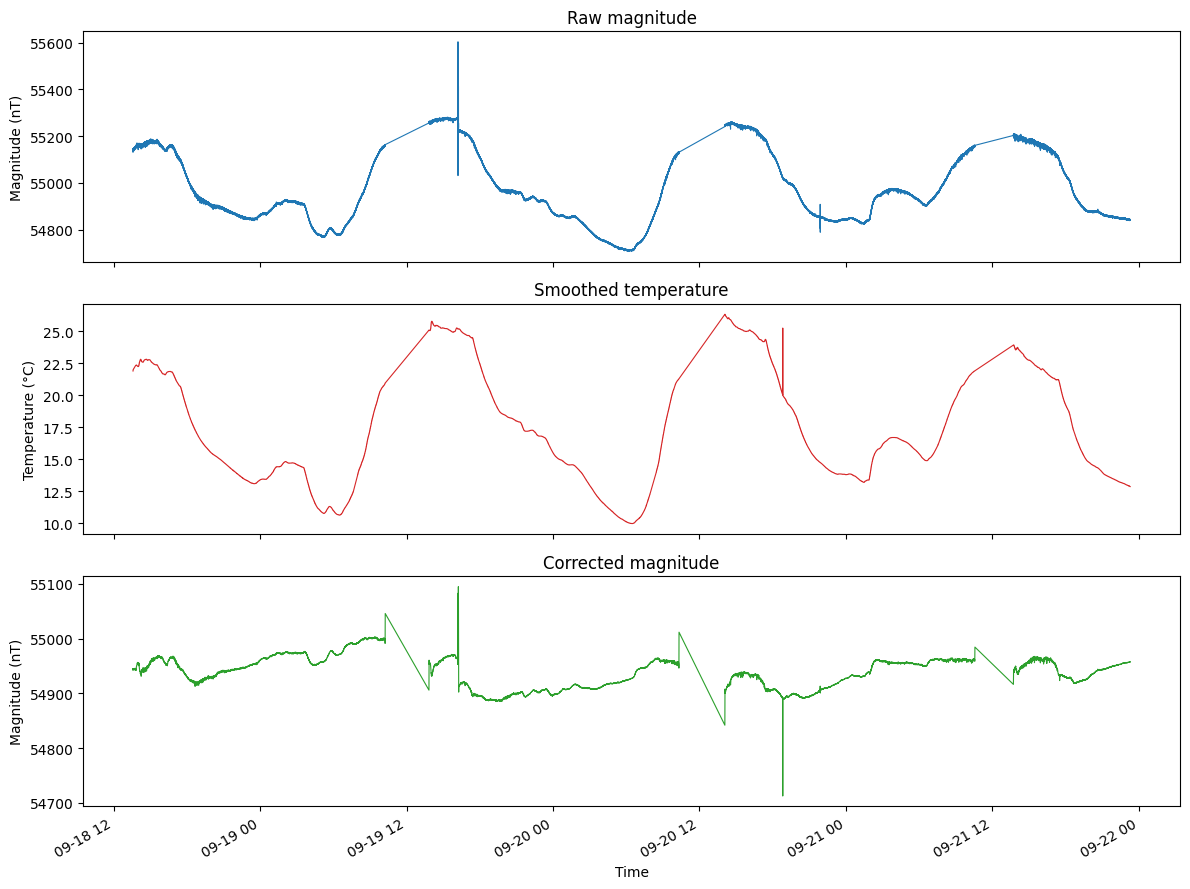

In [5]:
time, mag, mag_s, temp_s = load_time_mag_temp("data/creek-sep18-22.npz")
mag_corr, k = correct_magnitude(mag_s, temp_s)
print(f"k = {k:.3e} per C")
plot_correction(time, mag, temp_s, mag_corr)

In [10]:
time, mag, mag_s, temp_s = load_time_mag_temp("data/creek-sep18-22-2.npz")
mag_corr, k = correct_magnitude(mag_s, temp_s)
print(f"k = {k:.3e} per C")
plot_correction(time, mag, temp_s, mag_corr)

FileNotFoundError: [Errno 2] No such file or directory: 'data\\creek-sep18-22-2.npz'

In [11]:
time, mag, mag_s, temp_s = load_time_mag_temp("data/office-data.npz")
mag_corr, k = correct_magnitude(mag_s, temp_s)
print(f"k = {k:.3e} per C")
plot_correction(time, mag, temp_s, mag_corr)

FileNotFoundError: [Errno 2] No such file or directory: 'data\\office-data.npz'

In [12]:
def compare_to_reference(data_file, csv_file,
                         time_col="yyyy-MM-dd HH mm ss", mag_col="F (nT)",
                         align="segment", csv_tz="UTC", local_tz="UTC",
                         gap_minutes=30, trim_minutes=2):
    time, mag, mag_s, temp_s = load_time_mag_temp(data_file, local_tz=local_tz)
    mag_corr, k = correct_magnitude(mag_s, temp_s)

    ref = pd.read_csv(csv_file)
    s = ref[time_col].astype(str).str.strip()
    rt = pd.to_datetime(s, format="%Y-%m-%d %H %M %S", errors="coerce")
    if rt.isna().all():
        rt = pd.to_datetime(s)
    if rt.dt.tz is None:
        rt = rt.dt.tz_localize(csv_tz)
    rt = pd.DatetimeIndex(rt).tz_convert(local_tz)
    rm = pd.to_numeric(ref[mag_col], errors="coerce").to_numpy()

    ok = np.isfinite(rm) & (rt >= time[0]) & (rt <= time[-1])
    rt, rm = rt[ok], rm[ok]
    if len(rt) == 0:
        print("No overlap between the CSV and the data file. Check csv_tz.")

    t = (time - time[0]).total_seconds().to_numpy()
    gaps = np.where(np.diff(t) > gap_minutes * 60)[0]
    keep = np.ones(len(t), dtype=bool)
    for i in gaps:
        keep[(t > t[i] - trim_minutes * 60) & (t <= t[i])] = False
        keep[(t >= t[i + 1]) & (t < t[i + 1] + trim_minutes * 60)] = False
    edges = np.concatenate([[0], gaps + 1, [len(t)]])

    if align == "global":
        rm = rm - np.median(rm)
        mag_corr = mag_corr - np.nanmedian(mag_corr[keep])

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(rt, rm, lw=0.8, color="tab:orange", label="BOM")
    for j, (a, b) in enumerate(zip(edges[:-1], edges[1:])):
        kk = keep[a:b]
        tt, yy = time[a:b][kk], mag_corr[a:b][kk]
        if len(tt) == 0:
            continue
        if align == "segment":
            m = (rt >= tt[0]) & (rt <= tt[-1])
            if m.any():
                yy = yy - np.nanmedian(yy) + np.median(rm[m])
        ax.plot(tt, yy, lw=0.8, color="tab:green",
                label="Corrected magnitude" if j == 0 else "_nolegend_")
    ax.set_xlabel(f"Time ({local_tz})")
    ax.set_ylabel("Magnitude minus median (nT)" if align == "global" else "Magnitude (nT)")
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [13]:
compare_to_reference('data/creek-sep18-22.npz', 'data/bom-18th-22nd-sep.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'data/bom-18th-22nd-sep.csv'

In [ ]:
compare_to_reference('data/office-data.npz', 'data/bom-sep30-oct10.csv')